# Assignment 3(due on 11/11)

## Student:冷阔（12632764），Gtihub：Lk-ing
## 批改人：张鹏
## 得分：48/50

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset("/home/zhangp/桌面/A3/200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")  # 助教批改作业更改读取路径
xch4 = ds["xch4"]

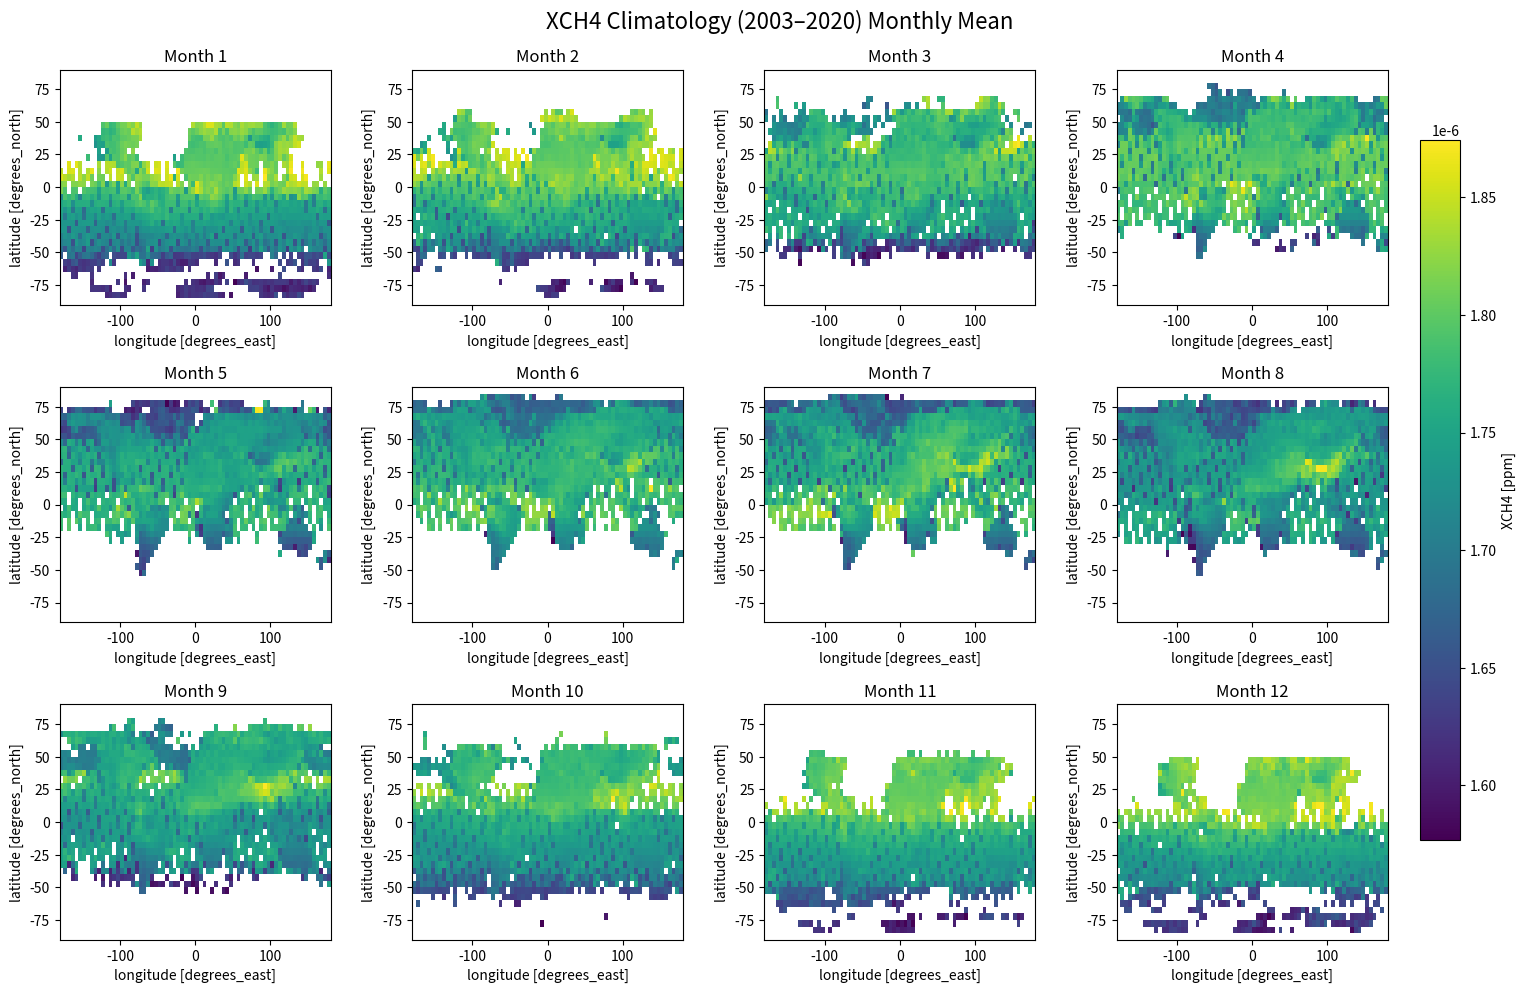

In [2]:
#1.1
clim = xch4.groupby("time.month").mean("time")
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()
cmap = plt.cm.viridis

for m_idx in range(12):
    ax = axes[m_idx]
    month_num = m_idx + 1
    im = clim.sel(month=month_num).plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=False
    )
    ax.set_title(f"Month {month_num}", fontsize=12)

fig.suptitle("XCH4 Climatology (2003–2020) Monthly Mean", fontsize=16, y=0.98)
fig.subplots_adjust(top=0.92, bottom=0.05, left=0.05, right=0.88, wspace=0.3, hspace=0.35)
cbar_ax = fig.add_axes([0.90, 0.15, 0.025, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax, label="XCH4 [ppm]")
plt.show()

/tmp/ipykernel_63950/2765647274.py:11: UserWarning: Glyph 8324 (\N{SUBSCRIPT FOUR}) missing from font(s) Source Han Sans SC.
  plt.tight_layout()
/home/zhangp/anaconda3/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8324 (\N{SUBSCRIPT FOUR}) missing from font(s) Source Han Sans SC.
  fig.canvas.print_figure(bytes_io, **kw)


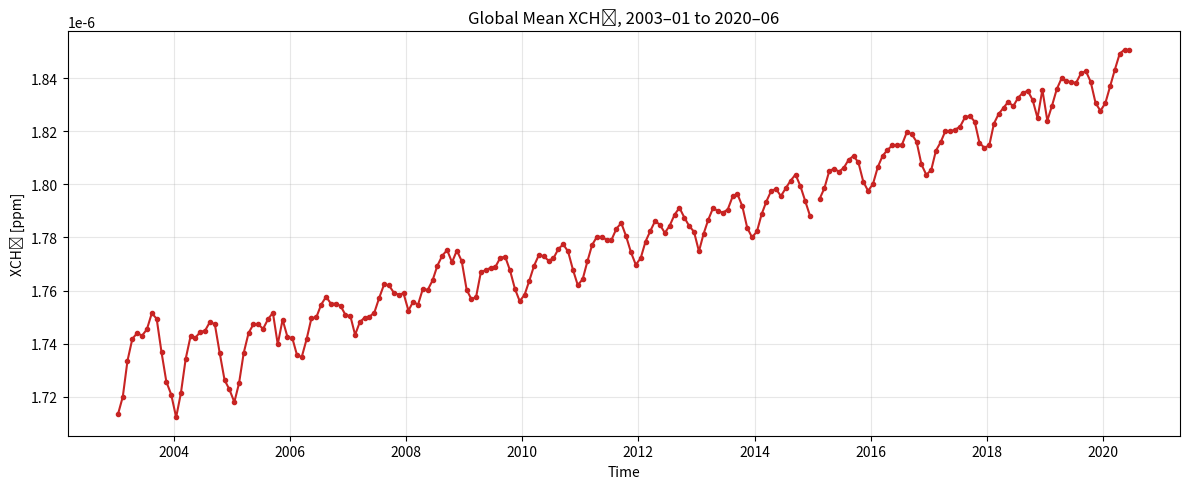

In [3]:
#1.2
lat_weight = np.cos(np.deg2rad(xch4.lat))
xch4_global_mean = xch4.weighted(lat_weight).mean(("lat", "lon"))

plt.figure(figsize=(12,5))
xch4_global_mean.plot(color="#c82423", marker="o", markersize=3, linestyle="-")
plt.title("Global Mean XCH₄, 2003–01 to 2020–06")
plt.ylabel("XCH₄ [ppm]")
plt.xlabel("Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_63950/3050333677.py:15: UserWarning: Glyph 8324 (\N{SUBSCRIPT FOUR}) missing from font(s) Source Han Sans SC.
  plt.tight_layout()
/home/zhangp/anaconda3/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8324 (\N{SUBSCRIPT FOUR}) missing from font(s) Source Han Sans SC.
  fig.canvas.print_figure(bytes_io, **kw)


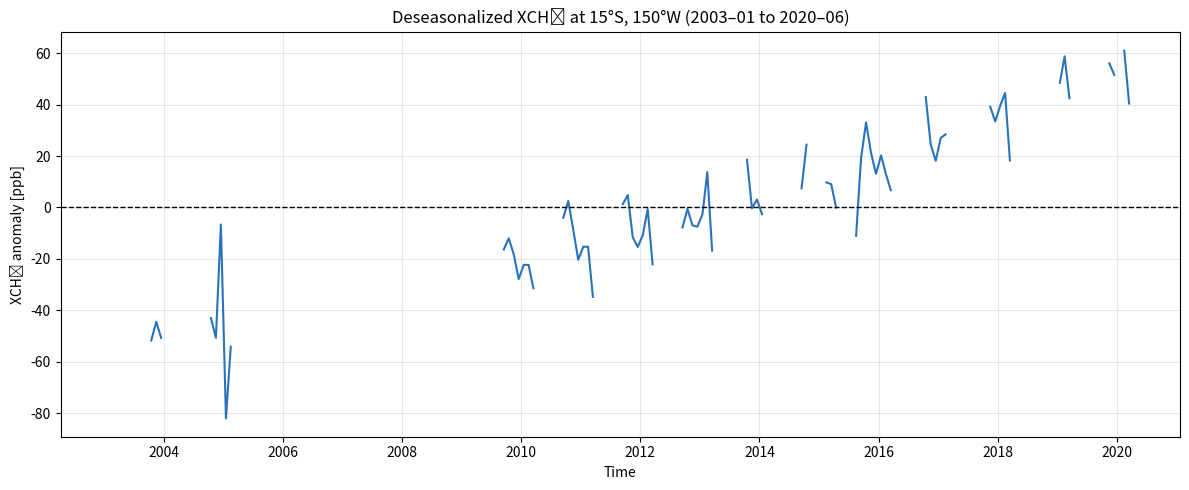

In [4]:
#1.3
ds = xr.open_dataset("/home/zhangp/桌面/A3/200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")  # 助教批改作业更改读取路径
xch4 = ds['xch4']
xch4_point = xch4.sel(lat=-15, lon=-150, method='nearest')
clim_month = xch4_point.groupby("time.month").mean("time")
xch4_anomaly = xch4_point.groupby("time.month") - clim_month
plt.figure(figsize=(12,5))
(xch4_anomaly * 1e9).plot(color="#2974b8")
plt.axhline(y=0, color="k", linestyle="--", lw=1)
plt.title("Deseasonalized XCH₄ at 15°S, 150°W (2003–01 to 2020–06)")
plt.ylabel("XCH₄ anomaly [ppb]")
plt.xlabel("Time")
plt.grid(alpha=0.3)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

### 第一题代码结果正确，但是单位细节错误结果文字描述不够充分，第一问原始摩尔分数未转换却标为 ppm，第二问未将摩尔分数乘以 1e6

### 得分：13/15
### --------------------------------------------------------------------------------------------

In [5]:
#2.1
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("/home/zhangp/桌面/A3/NOAA_NCDC_ERSST_v3b_SST.nc")  # 助教批改作业更改读取路径
sst = ds["sst"]

print("lat坐标：", sst.lat)
print("lon坐标：", sst.lon)

sst_n34 = sst.sel(lat=slice(-5, 5), lon=slice(190, 240)).mean(dim=["lat", "lon"])
sst_clim = sst_n34.groupby("time.month").mean("time")
sst_anomaly = sst_n34.groupby("time.month") - sst_clim

print(sst_anomaly)

lat坐标： <xarray.DataArray 'lat' (lat: 89)> Size: 356B
array([-88., -86., -84., -82., -80., -78., -76., -74., -72., -70., -68., -66.,
       -64., -62., -60., -58., -56., -54., -52., -50., -48., -46., -44., -42.,
       -40., -38., -36., -34., -32., -30., -28., -26., -24., -22., -20., -18.,
       -16., -14., -12., -10.,  -8.,  -6.,  -4.,  -2.,   0.,   2.,   4.,   6.,
         8.,  10.,  12.,  14.,  16.,  18.,  20.,  22.,  24.,  26.,  28.,  30.,
        32.,  34.,  36.,  38.,  40.,  42.,  44.,  46.,  48.,  50.,  52.,  54.,
        56.,  58.,  60.,  62.,  64.,  66.,  68.,  70.,  72.,  74.,  76.,  78.,
        80.,  82.,  84.,  86.,  88.], dtype=float32)
Coordinates:
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
Attributes:
    standard_name:  latitude
    pointwidth:     2.0
    gridtype:       0
    units:          degree_north
lon坐标： <xarray.DataArray 'lon' (lon: 180)> Size: 720B
array([  0.,   2.,   4.,   6.,   8.,  10.,  12.,  14.,  16.,  18.,  20.,  

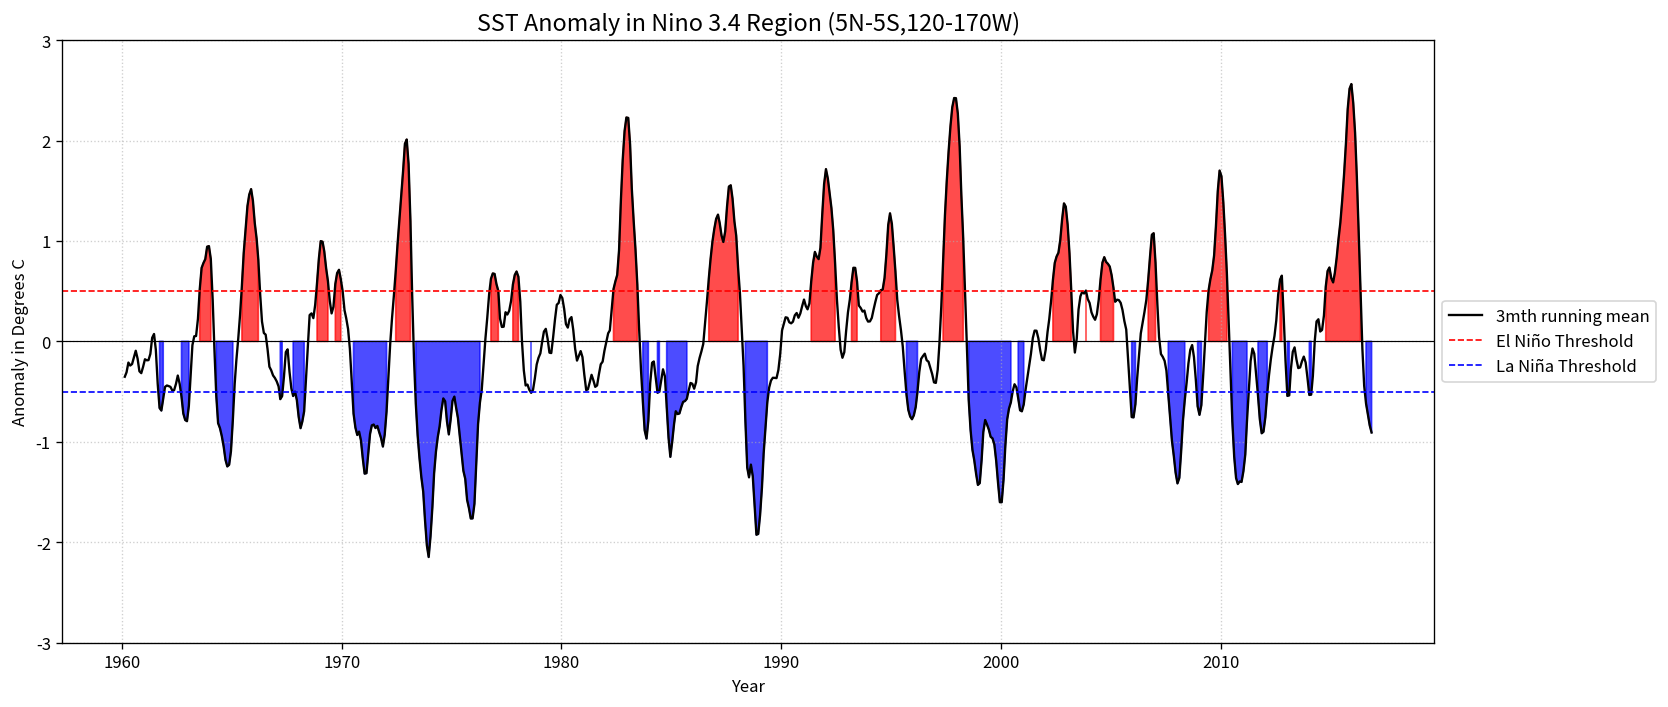

In [6]:
#2.2
import matplotlib.pyplot as plt

oni = sst_anomaly.rolling(time=3, center=True).mean()

plt.figure(figsize=(14,6), dpi=120)
plt.plot(oni.time, oni, color="black", linewidth=1.4, label="3mth running mean")

plt.axhline(y=0.5, color="red", linestyle="--", lw=1, label="El Niño Threshold")
plt.axhline(y=-0.5, color="blue", linestyle="--", lw=1, label="La Niña Threshold")
plt.axhline(y=0, color="black", lw=0.7)

plt.fill_between(oni.time, oni, 0, where=(oni >= 0.5), color="red", alpha=0.7)
plt.fill_between(oni.time, oni, 0, where=(oni <= -0.5), color="blue", alpha=0.7)

plt.title("SST Anomaly in Nino 3.4 Region (5N-5S,120-170W)", fontsize=14)
plt.ylabel("Anomaly in Degrees C")
plt.xlabel("Year")
plt.ylim(-3, 3)
plt.grid(linestyle=":", alpha=0.6)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 第二题代码结果正确，报告有文字解释

### 得分：20/20
### --------------------------------------------------------------------------------------------

In [7]:
#3.1
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

ds = xr.open_dataset("sst.mnmean.nc")
sst = ds["sst"]

monthly_clim = sst.groupby("time.month").mean("time")
sst_anom = sst.groupby("time.month") - monthly_clim
global_sst_anom = sst_anom.mean(dim=["lat", "lon"])

plt.figure(figsize=(14, 4))
plt.plot(global_sst_anom.time, global_sst_anom, color="#2266bb", linewidth=1.2)
plt.title("Global Mean SST Anomaly (Seasonal Cycle Removed)", fontsize=13)
plt.ylabel("SST Anomaly (°C)")
plt.xlabel("Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: b'/home/zhangp/\xe6\xa1\x8c\xe9\x9d\xa2/A3/12632764/sst.mnmean.nc'

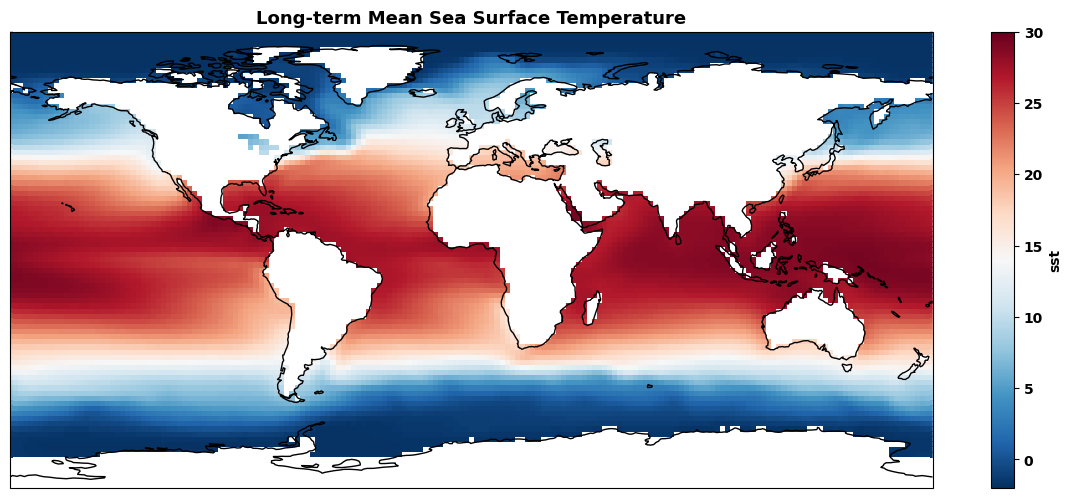

In [23]:
#3.2
#1多年平均海温空间图
sst_mean = sst.mean("time")
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=-2, vmax=30)
ax.coastlines()
ax.set_title("Long-term Mean Sea Surface Temperature", fontsize=13)
plt.tight_layout()
plt.show()


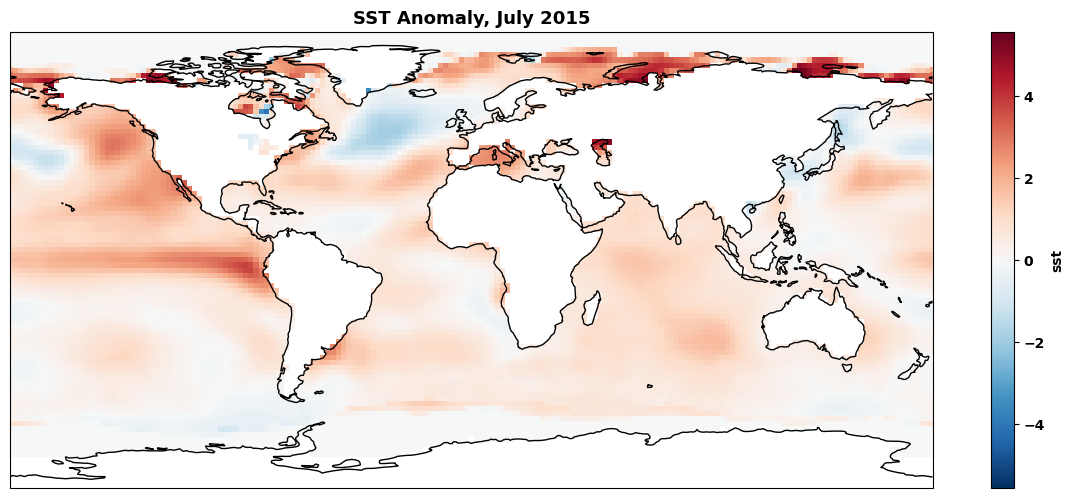

In [24]:
#2单月距平场（2015-07）
sst_anom_201507 = sst_anom.sel(time="2015-07")
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
sst_anom_201507.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r")
ax.coastlines()
ax.set_title("SST Anomaly, July 2015", fontsize=13)
plt.tight_layout()
plt.show()

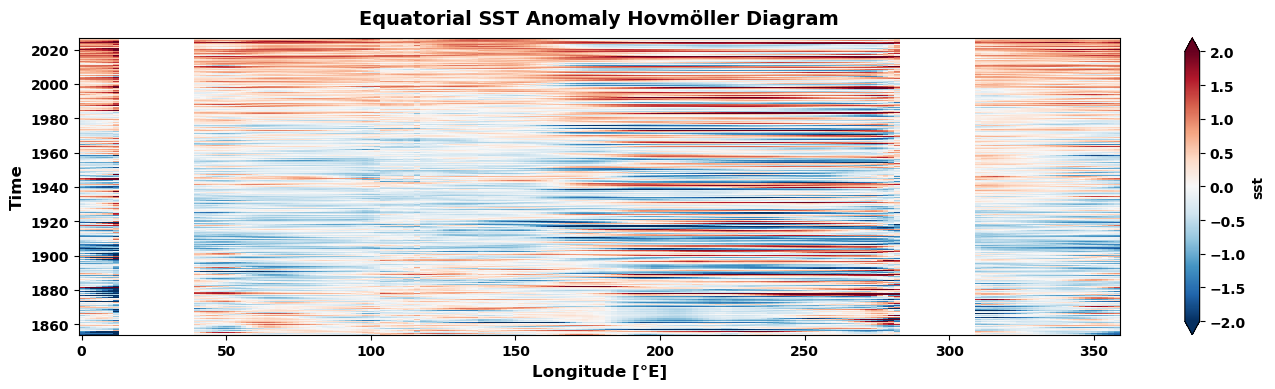

In [32]:
# 3赤道Hovmöller图（-5~5°）
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

ds = xr.open_dataset("sst.mnmean.nc")
sst = ds["sst"]

monthly_clim = sst.groupby("time.month").mean("time")
sst_anom = sst.groupby("time.month") - monthly_clim

sst_eq_anom = sst_anom.sel(lat=slice(5, -5)).mean("lat", skipna=True)

fig = plt.figure(figsize=(14,4))
ax = fig.add_subplot(111)

pcm = sst_eq_anom.plot(ax=ax, cmap="RdBu_r", vmin=-2, vmax=2, extend="both")
ax.set_title("Equatorial SST Anomaly Hovmöller Diagram", fontsize=14, pad=10)
ax.set_xlabel("Longitude [°E]", fontsize=12)
ax.set_ylabel("Time", fontsize=12)
plt.tight_layout()
plt.show()

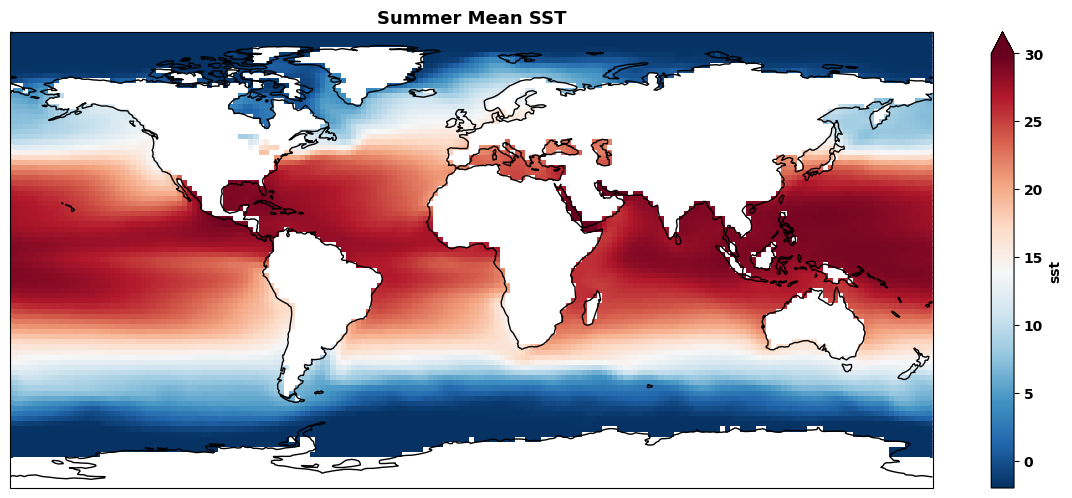

In [26]:
# 4夏季平均海温
sst_summer = sst.sel(time=sst["time.month"].isin([6,7,8])).mean("time")
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
sst_summer.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=-2, vmax=30)
ax.coastlines()
ax.set_title("Summer Mean SST", fontsize=13)
plt.tight_layout()
plt.show()

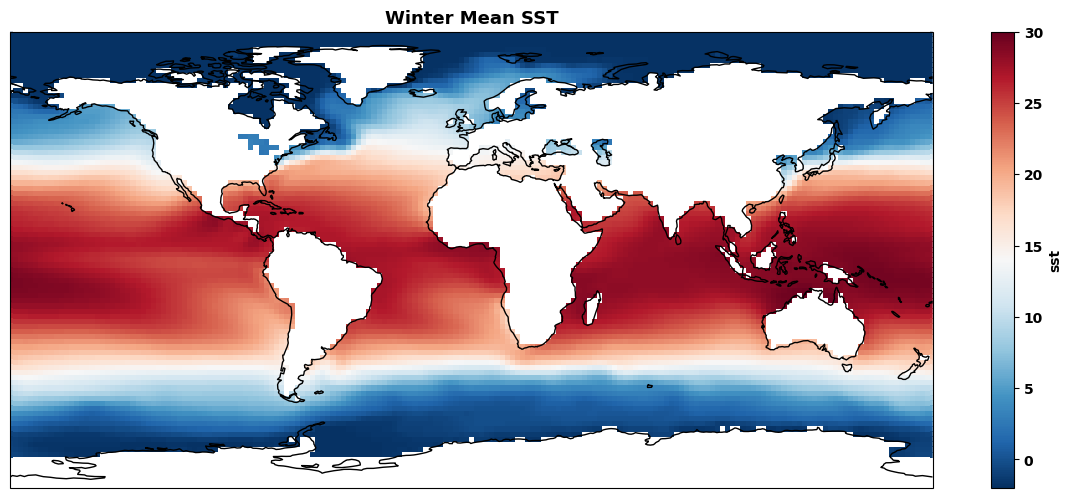

In [27]:
# 5冬季平均海温
sst_winter = sst.sel(time=sst["time.month"].isin([12,1,2])).mean("time")
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
sst_winter.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=-2, vmax=30)
ax.coastlines()
ax.set_title("Winter Mean SST", fontsize=13)
plt.tight_layout()
plt.show()

### 第三题代码结果正确，报告有文字解释

### 得分：15/15
### --------------------------------------------------------------------------------------------